In [24]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 67  # seed
np.random.seed(SEED)

In [25]:
import os


def is_dataset_root(path):
    has_manifest = (path / 'train.csv').is_file() and (path / 'train_images').is_dir()
    has_class_folders = path.is_dir() and sum(
        class_dir.is_dir() and any(class_dir.glob('*.jpg'))
        for class_dir in path.iterdir()
    ) >= 10
    return has_manifest or has_class_folders


candidates = []
configured_root = os.environ.get('EUROSAT_DIR')
if configured_root:
    candidates.append(Path(configured_root).expanduser())

for base in (Path.cwd(), *Path.cwd().parents):
    candidates.extend([
        base / 'DATASET',
        base / 'dataset',
        base,
        base / 'EuroSAT_RGB' / 'EuroSAT_RGB',
        base / 'EuroSAT_RGB',
        base / 'EuroSAT' / '2750',
        base / 'EuroSAT',
    ])

ROOT = next(
    (candidate.resolve() for candidate in candidates if is_dataset_root(candidate)),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        'EuroSAT dataset was not found. Keep the DATASET folder beside the notebook '
        'or set the EUROSAT_DIR environment variable to the dataset root.'
    )

if (ROOT / 'train.csv').is_file():
    df = pd.read_csv(ROOT / 'train.csv')
    required_columns = {'path', 'label'}
    if not required_columns.issubset(df.columns):
        raise ValueError('train.csv must contain the columns: path and label.')
    df['filepath'] = df['path'].map(lambda path: str((ROOT / path).resolve()))
else:
    rows = []
    for class_dir in sorted(ROOT.iterdir()):
        if class_dir.is_dir():
            for img in sorted(class_dir.glob('*.jpg')):
                rows.append({'filepath': str(img.resolve()), 'label': class_dir.name})
    df = pd.DataFrame(rows)

In [26]:
import tensorflow as tf

TEST_DIR = ROOT / 'test_images'
TEST_IMAGES = sorted(TEST_DIR.glob('*.jpg'))
sample_submission_path = ROOT / 'sample_submission.csv'
sample_submission = pd.read_csv(sample_submission_path)

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Test images:', len(TEST_IMAGES))
print('Submission columns:', sample_submission.columns.tolist())
print(sample_submission.head())

TensorFlow: 2.22.0-rc0
GPU devices: []
Test images: 5400
Submission columns: ['id', 'label']
   id  label
0   0      0
1   1      0
2   2      0
3   3      0
4   4      0


In [27]:
print('total imágenes etiquetadas:', len(df))
print('clases:', df['label'].nunique())      # esperado: 10
print('nulos:', df.isnull().sum().sum())     # esperado: 0

# Balance de clases
print(df['label'].value_counts())

# Verificar que las imágenes abren y son 64x64 RGB
img = Image.open(df.loc[0, 'filepath'])
print('size:', img.size, '| mode:', img.mode)  # esperado: (64, 64) RGB

total imágenes etiquetadas: 21600
clases: 10
nulos: 0
label
Residential             2400
HerbaceousVegetation    2400
AnnualCrop              2400
SeaLake                 2400
Forest                  2400
Highway                 2000
River                   2000
PermanentCrop           2000
Industrial              2000
Pasture                 1600
Name: count, dtype: int64
size: (64, 64) | mode: RGB


## 1. Exploración y preparación

La etiqueta de validación se reserva exclusivamente desde `train.csv` mediante un split estratificado. `test_images` y `sample_submission.csv` no se usan para ajustar el modelo; se consultan solo al generar la entrega.

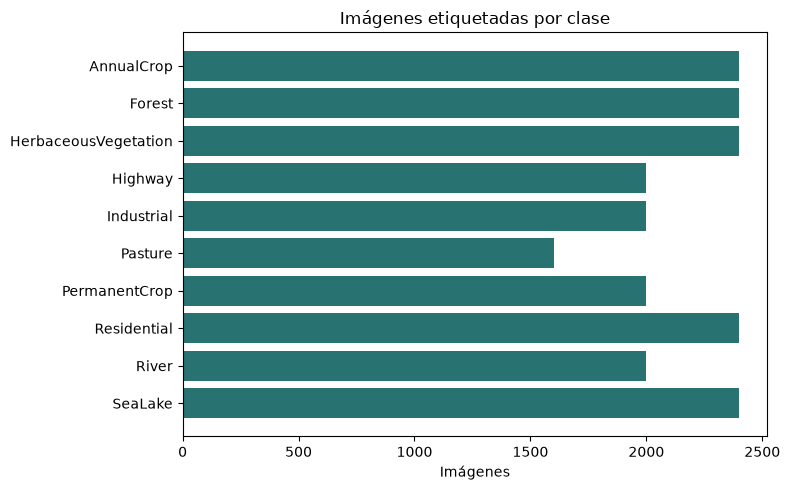

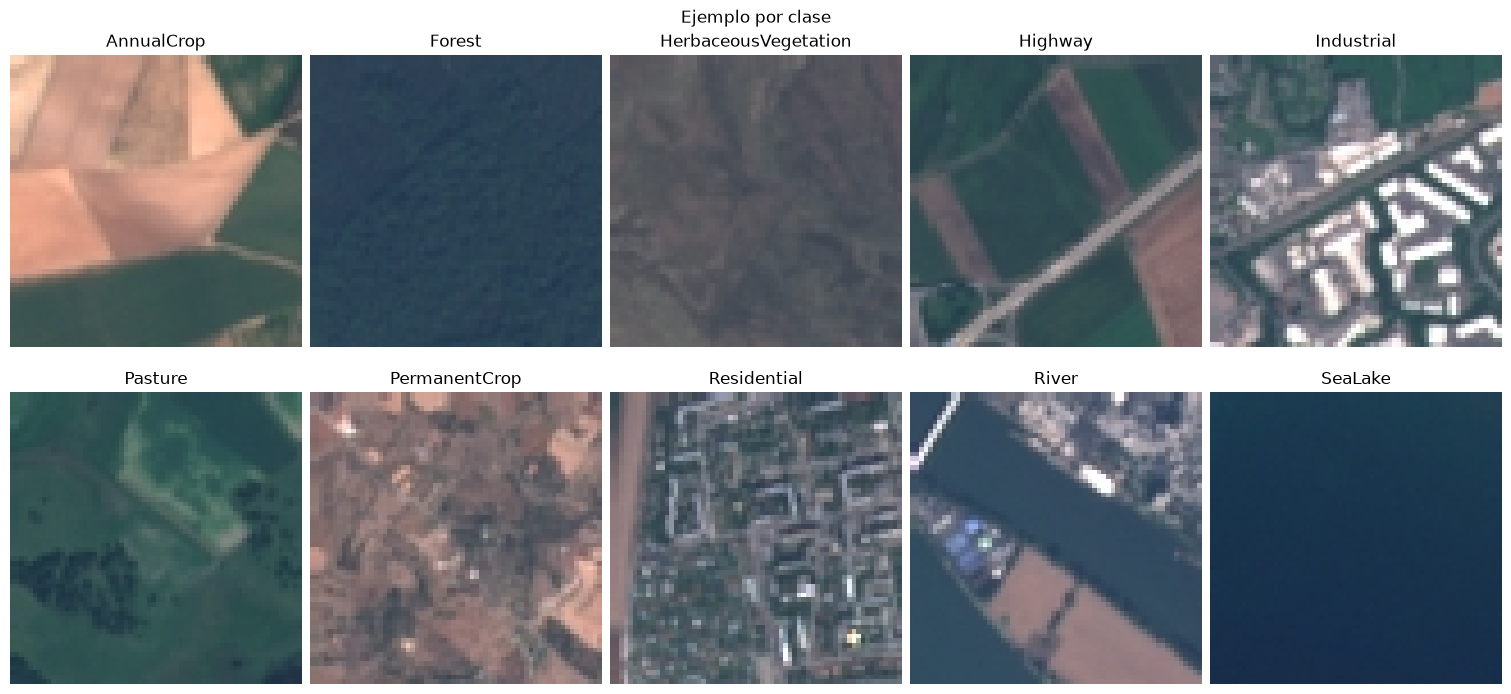

Dimensiones esperadas: 64 x 64 x 3
Rango de imágenes por clase: 1600 a 2400


In [28]:
classes = sorted(df['label'].unique())
class_to_index = {name: index for index, name in enumerate(classes)}

class_counts = df['label'].value_counts().reindex(classes)
fig, axis = plt.subplots(figsize=(8, 5))
axis.barh(class_counts.index, class_counts.values, color='#287271')
axis.set_title('Imágenes etiquetadas por clase')
axis.set_xlabel('Imágenes')
axis.invert_yaxis()
fig.tight_layout()

sample_rows = df.groupby('label', group_keys=False).sample(n=1, random_state=SEED)
fig_samples, sample_axes = plt.subplots(
    2, 5, figsize=(15, 7), constrained_layout=True
)
for axis, (_, row) in zip(sample_axes.flat, sample_rows.iterrows()):
    with Image.open(row['filepath']) as image:
        axis.imshow(image.convert('RGB'))
    axis.set_title(row['label'])
    axis.axis('off')
fig_samples.suptitle('Ejemplo por clase')
plt.show()

print('Dimensiones esperadas: 64 x 64 x 3')
print('Rango de imágenes por clase:', int(class_counts.min()), 'a', int(class_counts.max()))

## 2. Split estratificado y `tf.data`

Se reserva el 20 % del conjunto etiquetado para validación con proporciones de clase conservadas. Las imágenes se decodifican desde disco como RGB; el preprocesamiento y la normalización se integrarán en el modelo para que inferencia use exactamente el mismo flujo.

In [29]:
from sklearn.model_selection import train_test_split

VAL_SIZE = 0.20
all_paths = df['filepath'].to_numpy(dtype=str)
all_labels = df['label'].map(class_to_index).to_numpy(dtype=np.int32)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=all_labels,
)

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 128 if tf.config.list_physical_devices('GPU') else 64


def decode_image(path, label):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return image, label


def make_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(decode_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.cache()
    if training:
        dataset = dataset.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)

train_counts = np.bincount(train_labels, minlength=len(classes))
class_weights = {
    index: float(np.sqrt(len(train_labels) / (len(classes) * count)))
    for index, count in enumerate(train_counts)
}

print(f'Train: {len(train_paths)} | validación: {len(val_paths)} | batch: {BATCH_SIZE}')
print('Train class counts:', dict(zip(classes, train_counts.tolist())))
print('GPU devices:', tf.config.list_physical_devices('GPU'))

Train: 17280 | validación: 4320 | batch: 64
Train class counts: {'AnnualCrop': 1920, 'Forest': 1920, 'HerbaceousVegetation': 1920, 'Highway': 1600, 'Industrial': 1600, 'Pasture': 1280, 'PermanentCrop': 1600, 'Residential': 1920, 'River': 1600, 'SeaLake': 1920}
GPU devices: []


## 3. CNN y entrenamiento

Arquitectura convolucional compacta para imágenes de 64 × 64: bloques Conv2D + BatchNormalization, aumento aleatorio solo durante entrenamiento, regularización L2 y dropout. Se optimiza con Adam y se conserva el checkpoint con mejor `val_accuracy`; `EarlyStopping` y `ReduceLROnPlateau` reducen sobreajuste y ajustan la tasa de aprendizaje.

In [30]:
keras = tf.keras
layers = keras.layers
regularizers = keras.regularizers


def build_model(input_shape=(64, 64, 3), num_classes=10):
    augmentation = keras.Sequential(
        [
            layers.RandomFlip('horizontal_and_vertical'),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
            layers.RandomContrast(0.10),
        ],
        name='data_augmentation',
    )

    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = augmentation(x)

    for filters in (32, 64, 128, 192):
        for _ in range(2):
            x = layers.Conv2D(
                filters,
                kernel_size=3,
                padding='same',
                use_bias=False,
                kernel_regularizer=regularizers.l2(1e-4),
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('swish')(x)
        x = layers.MaxPooling2D(pool_size=2)(x)
        x = layers.SpatialDropout2D(0.10)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        256,
        activation='swish',
        kernel_regularizer=regularizers.l2(1e-4),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='eurosat_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=3e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
            keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_accuracy'),
        ],
    )
    return model


model = build_model(num_classes=len(classes))
smoke_test_output = model(tf.zeros((2, 64, 64, 3), dtype=tf.uint8), training=False)
print('Forward-pass shape:', smoke_test_output.shape)
model.summary()

Forward-pass shape: (2, 10)


Model: "eurosat_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_8             │ (None, 32, 32, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_9             │ (None, 16, 16, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 895,850 (3.42 MB)

 Trainable params: 893,674 (3.41 MB)

 Non-trainable params: 2,176 (8.50 KB)

## 4. Entrenamiento y checkpoint

El entrenamiento puede tardar en CPU. Si el kernel detecta una GPU compatible, `tf.data` y Keras la usarán automáticamente. Se guardan el mejor modelo, el historial y el orden de clases en `artifacts/`.

Epoch 1/40


c:\Users\mark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


270/270 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.5655 - loss: 1.3803 - top3_accuracy: 0.8583
Epoch 1: val_accuracy improved from None to 0.11597, saving model to C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts\eurosat_cnn.keras

Epoch 1: finished saving model to C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts\eurosat_cnn.keras
270/270 ━━━━━━━━━━━━━━━━━━━━ 127s 420ms/step - accuracy: 0.5655 - loss: 1.3803 - top3_accuracy: 0.8583 - val_accuracy: 0.1160 - val_loss: 4.4897 - val_top3_accuracy: 0.4324 - learning_rate: 3.0000e-04
Epoch 2/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.6832 - loss: 1.0088 - top3_accuracy: 0.9292
Epoch 2: val_accuracy improved from 0.11597 to 0.57894, saving model to C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts\eurosat_cnn.keras

Epoch 2: finished saving model to C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts\eurosat_cnn.keras
270/270 ━━━━━━━━━━━━━━━━━━━━ 110s 406ms/step - accuracy

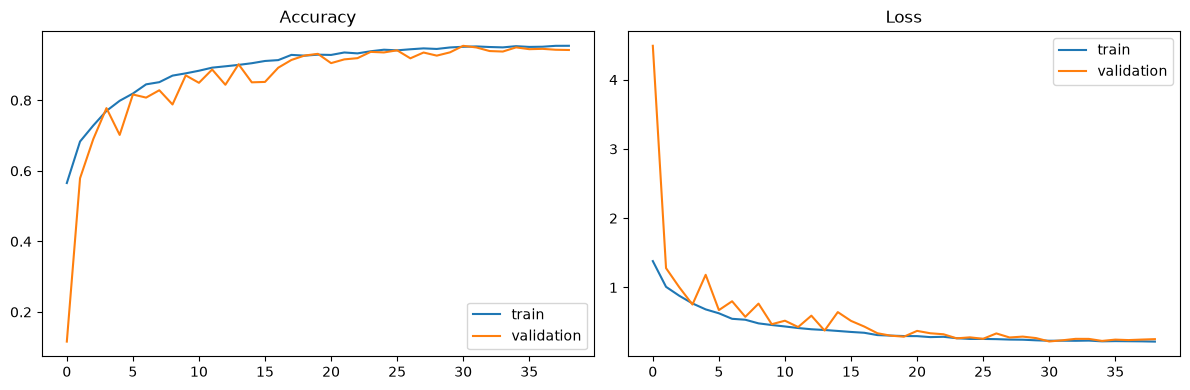

Best model: C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts\eurosat_cnn.keras
Artifact directory: C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts


In [31]:
import json
from datetime import datetime
from sklearn.metrics import f1_score

MAX_EPOCHS = 40
ARTIFACT_DIR = ROOT.parent / 'artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = ARTIFACT_DIR / 'eurosat_cnn.keras'

callbacks = [
    keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
)

best_model = keras.models.load_model(BEST_MODEL_PATH)
validation_metrics = best_model.evaluate(val_ds, return_dict=True, verbose=1)
val_probabilities = best_model.predict(val_ds, verbose=0)
val_predictions = val_probabilities.argmax(axis=1)
validation_metrics['macro_f1'] = float(
    f1_score(val_labels, val_predictions, average='macro')
)
print('Validation metrics:', validation_metrics)

with (ARTIFACT_DIR / 'class_names.json').open('w', encoding='utf-8') as file:
    json.dump(classes, file, ensure_ascii=False, indent=2)
pd.DataFrame(history.history).to_csv(ARTIFACT_DIR / 'training_history.csv', index=False)

experiment_log = {
    'timestamp': datetime.now().astimezone().isoformat(timespec='seconds'),
    'seed': SEED,
    'validation_fraction': VAL_SIZE,
    'epochs_requested': MAX_EPOCHS,
    'epochs_completed': len(history.history['loss']),
    'batch_size': BATCH_SIZE,
    'architecture': '4 convolution blocks with 32, 64, 128, and 192 filters; global average pooling; dense 256',
    'optimizer': 'Adam',
    'initial_learning_rate': 3e-4,
    'l2_strength': 1e-4,
    'dropout': {'spatial': 0.10, 'dense': 0.40},
    'augmentations': ['horizontal_and_vertical_flip', 'rotation_0.08', 'zoom_0.10', 'contrast_0.10'],
    'class_weights': {
        classes[index]: weight for index, weight in class_weights.items()
    },
    'validation_metrics': {
        name: float(value) for name, value in validation_metrics.items()
    },
}
with (ARTIFACT_DIR / 'experiment_log.json').open('w', encoding='utf-8') as file:
    json.dump(experiment_log, file, ensure_ascii=False, indent=2)
with (ARTIFACT_DIR / 'experiment_runs.jsonl').open('a', encoding='utf-8') as file:
    file.write(json.dumps(experiment_log, ensure_ascii=False) + '\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='validation')
axes[0].set_title('Accuracy')
axes[0].legend()
axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='validation')
axes[1].set_title('Loss')
axes[1].legend()
fig.tight_layout()
plt.show()

print('Best model:', BEST_MODEL_PATH)
print('Artifact directory:', ARTIFACT_DIR)

## 5. Evaluación de validación

Estas métricas estiman generalización usando únicamente el split retenido de `train.csv`. La validación no participa en el ajuste de pesos y el conjunto de prueba aún no se consulta.

Validation macro F1: 0.9541248138965356
                      precision    recall  f1-score   support

          AnnualCrop     0.9740    0.9375    0.9554       480
              Forest     0.9446    0.9938    0.9685       480
HerbaceousVegetation     0.9302    0.9167    0.9234       480
             Highway     0.9742    0.9425    0.9581       400
          Industrial     0.9841    0.9300    0.9563       400
             Pasture     0.9679    0.9437    0.9557       320
       PermanentCrop     0.9093    0.9275    0.9183       400
         Residential     0.9125    1.0000    0.9543       480
               River     0.9770    0.9550    0.9659       400
             SeaLake     0.9874    0.9833    0.9854       480

            accuracy                         0.9544      4320
           macro avg     0.9561    0.9530    0.9541      4320
        weighted avg     0.9553    0.9544    0.9544      4320



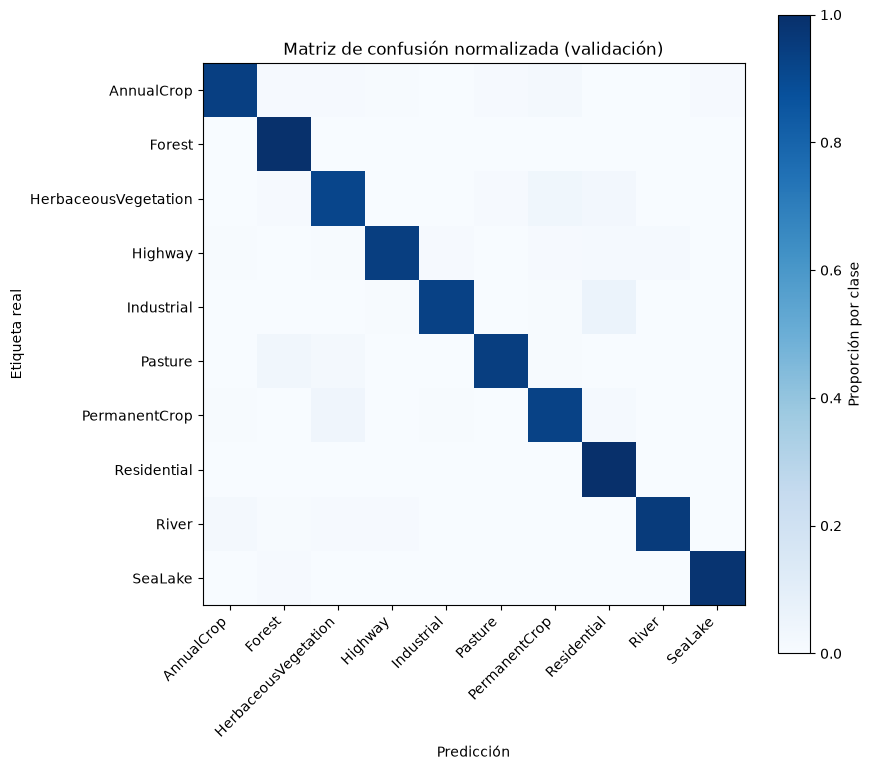

In [32]:
from sklearn.metrics import classification_report, confusion_matrix

print('Validation macro F1:', validation_metrics['macro_f1'])
print(
    classification_report(
        val_labels,
        val_predictions,
        labels=np.arange(len(classes)),
        target_names=classes,
        digits=4,
        zero_division=0,
    )
)

confusion = confusion_matrix(val_labels, val_predictions, normalize='true')
fig, axis = plt.subplots(figsize=(9, 8))
image = axis.imshow(confusion, cmap='Blues', vmin=0, vmax=1)
axis.set_xticks(np.arange(len(classes)), labels=classes, rotation=45, ha='right')
axis.set_yticks(np.arange(len(classes)), labels=classes)
axis.set_xlabel('Predicción')
axis.set_ylabel('Etiqueta real')
axis.set_title('Matriz de confusión normalizada (validación)')
fig.colorbar(image, ax=axis, label='Proporción por clase')
fig.tight_layout()
plt.show()

## 6. Predicciones para la competencia

Este paso se ejecuta después de finalizar la selección del modelo con validación. Solo lee las imágenes de `test_images` y los IDs de `sample_submission.csv`; no busca ni crea etiquetas de prueba.

In [37]:
test_items = sorted(
    (path for path in TEST_DIR.iterdir() if path.suffix.lower() == '.jpg'),
    key=lambda path: int(path.stem),
)
test_ids = [int(path.stem) for path in test_items]
if test_ids != list(range(len(test_items))):
    raise ValueError('Expected test image filenames to be numbered consecutively from 00000.')


def decode_test_image(path):
    return tf.io.decode_jpeg(tf.io.read_file(path), channels=3)


test_ds = tf.data.Dataset.from_tensor_slices(
    np.asarray([str(path) for path in test_items], dtype=str)
)
test_ds = test_ds.map(decode_test_image, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

inference_model = keras.models.load_model(BEST_MODEL_PATH)
test_probabilities = inference_model.predict(test_ds, verbose=1)
test_class_indices = test_probabilities.argmax(axis=1).astype(int)
submission = pd.DataFrame({
    'id': [f'test_{image_id + 1:05d}' for image_id in test_ids],
    'label': test_class_indices,
})

submission_path = ARTIFACT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
print('Predictions written:', submission_path)
print(submission.head())

85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step
Predictions written: C:\Users\mark\Desktop\PROYECTO CNN\CODE\CNN_EuroSAT\artifacts\submission.csv
           id  label
0  test_00001      8
1  test_00002      6
2  test_00003      4
3  test_00004      1
4  test_00005      0
